# Kalibrace multispektrální kamery, pokročilá verze: geometrie pásem, chyby NDVI, termální a panchromatické pásmo

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kalibrace multispektrální kamery](https://openskylab.space/edu_viz_multispectral_calibration.html) · [English version](multispectral_calibration_pro_en.ipynb)

Pokročilá verze notebooku o kalibraci multispektrální kamery. Kamera MicaSense Altum-PT má sedm samostatných objektivů: pět multispektrálních, jeden panchromatický a jeden termální. Na skutečném snímku z letu zjistíš, jak se pásma vůči sobě posouvají, otáčejí a liší měřítkem a co to dělá s NDVI, jak se chyba kalibrace jednoho pásma přenáší do indexů, jak souvisí teplota povrchu s vegetací a co umí a neumí zostření panchromatickým pásmem.

**Cíl:** změřit paralaxu mezi pásmy a z ní vzdálenost kamery od panelu, sesadit pásma afinní transformací a porovnat ji s metadaty soustavy kamer, odvodit citlivost NDVI na chybu kalibrace, přenést NDVI na mřížku termokamery a porovnat ho s teplotou povrchu a zostřit pásma panchromatickým snímkem.

**Data:** dva snímky (všech 7 pásem) kamery MicaSense Altum-PT s DLS 2 z ukázkových dat MicaSense (repozitář micasense/imageprocessing, licence MIT): IMG_0000 (panel RP06, 15. 8. 2022 19:16 UTC) a IMG_0010 (let o 3 minuty později, asi 97 m nad terénem), 48,51° s. š., 122,42° z. d. Pět multispektrálních pásem má 2064 × 1544 pixelů, panchromatické 4112 × 3008 a termální 320 × 256. Termální pásmo je v setinách kelvinu a kamera počítá s emisivitou 1,0 (přesnost podle výrobce ±5 K).

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 60 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a snímky

Načteme všech sedm pásem snímku z letu a pět pásem snímku panelu. Tabulka ukazuje, že každé pásmo má vlastní objektiv s trochu jinou ohniskovou vzdáleností a že objektivy jsou od sebe posunuté o centimetry (RigTranslations v metadatech, vůči zelenému pásmu).

In [1]:
import re, io, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from matplotlib.path import Path

In [2]:
BASE = "https://media.githubusercontent.com/media/micasense/imageprocessing/master/data/ALTUM-PT/"
def fetch(name, tries=5):
    for i in range(tries):
        try:
            r = requests.get(BASE + name, timeout=120); r.raise_for_status(); return r.content
        except requests.RequestException as e:
            print(name, type(e).__name__, "– zkusím znovu"); time.sleep(3 * (i + 1))
    raise RuntimeError("Snímky se nepodařilo stáhnout.")

def xmp_reader(raw):
    x = raw[raw.find(b"<x:xmpmeta"): raw.find(b"</x:xmpmeta>")].decode()
    def get(tag):
        m = re.search(rf"<{tag}>(.*?)</{tag}>", x, re.S)
        if not m: return None
        v = m.group(1)
        if "<rdf:li>" in v:
            return [float(s) for li in re.findall(r"<rdf:li>\s*([^<]+?)\s*</rdf:li>", v) for s in li.split(",")]
        if "," in v: return [float(s) for s in v.split(",")]
        try: return float(v)
        except ValueError: return v.strip()
    return get

def load(name):
    """Načte jedno pásmo: pole DN a slovník metadat (radiometrie, DLS, geometrie objektivu a soustavy kamer)."""
    raw = fetch(name); im = Image.open(io.BytesIO(raw)); ex = im.getexif(); sub = ex.get_ifd(0x8769); gps = ex.get_ifd(0x8825); g = xmp_reader(raw)
    m = dict(band=g("Camera:BandName"), wl=g("Camera:CentralWavelength"), exposure=float(sub.get(33434, 1.0)), gain=sub.get(34867, 100) / 100,
             black=float(np.mean(ex[50714])) if 50714 in ex else 0.0, bits=ex[258], cal=g("MicaSense:RadiometricCalibration"),
             vig_c=g("Camera:VignettingCenter"), vig_p=g("Camera:VignettingPolynomial"),
             vig_2d=g("Camera:VignettingPolynomial2D"), vig_e=g("Camera:VignettingPolynomial2DName"),
             albedo=g("Camera:Albedo"), area=g("Camera:ReflectArea"), time=ex[306], alt=float(gps[6]),
             E_h=g("DLS:HorizontalIrradiance"), sun_el=g("DLS:SolarElevation"),
             f=g("Camera:PerspectiveFocalLength"), pp=g("Camera:PrincipalPoint"), pitch=1 / float(sub[41486]),   # mm, mm, mm
             rig_t=g("Camera:RigTranslations"), rig_r=g("Camera:RigRelatives"))
    if m["E_h"] is not None: m["E_h"] *= 0.01    # µW/cm²/nm → W/m²/nm
    return np.array(im).astype(np.float32), m

def vig_factor(m, shape):
    y, x = np.indices(shape)
    if m["vig_c"] is not None:
        return 1 / np.polyval(list(m["vig_p"])[::-1] + [1.0], np.hypot(x - m["vig_c"][0], y - m["vig_c"][1]))
    xv, yv = x / shape[1], y / shape[0]
    return 1 / sum(c * xv ** m["vig_e"][2 * i] * yv ** m["vig_e"][2 * i + 1] for i, c in enumerate(m["vig_2d"]))

def radiance(dn, m):
    """Radiance (W/m²/sr/nm) modelem MicaSense jako v základní verzi."""
    y, x = np.indices(dn.shape)
    a1, a2, a3 = m["cal"]
    R = 1 / (1 + a2 * y / m["exposure"] - a3 * y)
    return (np.clip(vig_factor(m, dn.shape) * R * (dn - m["black"]), 0, None) / (m["gain"] * m["exposure"]) * a1 / 2 ** m["bits"]).astype(np.float32)

PANEL = {b: load(f"IMG_0000_{b}.tif") for b in range(1, 6)}
FLIGHT = {b: load(f"IMG_0010_{b}.tif") for b in range(1, 8)}     # 6 panchromatické, 7 termální
tab = pd.DataFrame({b: {"pásmo": m["band"], "λ (nm)": m["wl"], "pixelů": f"{dn.shape[1]} × {dn.shape[0]}", "f (mm)": m["f"],
                        "pixel (µm)": 1000 * m["pitch"], "posun vůči pásmu 2, x y z (mm)": m["rig_t"]}
                    for b, (dn, m) in FLIGHT.items()}).T
print(tab.to_string())
print("panel:", PANEL[1][1]["time"], f"GPS {PANEL[1][1]['alt']:.1f} m n. m.", " let:", FLIGHT[1][1]["time"], f"GPS {FLIGHT[1][1]['alt']:.1f} m n. m.")

      pásmo   λ (nm)       pixelů     f (mm) pixel (µm)     posun vůči pásmu 2, x y z (mm)
1      Blue    475.0  2064 × 1544     7.8828       3.45     [-49.01269, -0.2451, 0.718963]
2     Green    560.0  2064 × 1544   7.862345       3.45                    [0.0, 0.0, 0.0]
3       Red    668.0  2064 × 1544   7.892093       3.45   [-12.10394, 24.29775, -0.620508]
4       NIR    842.0  2064 × 1544   7.867275       3.45  [-24.59074, -0.194283, -0.968696]
5  Red edge    717.0  2064 × 1544   7.891018       3.45   [-36.54579, 24.43246, -0.660754]
6   Panchro    634.5  4112 × 3008  16.577383       3.45    [-37.06401, -47.09952, 4.89484]
7      LWIR  11000.0    320 × 256   4.444976       12.0    [-8.32026, -45.82793, -4.55625]
panel: 2022:08:15 19:16:11 GPS 12.0 m n. m.  let: 2022:08:15 19:18:54 GPS 108.0 m n. m.


## 2. Paralaxa mezi pásmy

Dva objektivy vzdálené o T vidí stejný bod ve vzdálenosti H posunutý o Δ = T · f / (H · p) pixelů, kde f je ohnisková vzdálenost a p velikost pixelu snímače. Ze 100 m je to kolem jednoho pixelu, z metru ze země přes sto. Část posunu nezávisí na vzdálenosti (objektivy nejsou přesně rovnoběžné), proto porovnáme posun na snímku panelu a na snímku z letu: rozdíl je téměř čistá paralaxa panelu.

          Tx (mm)  Ty (mm)  panel dx  panel dy  let dx  let dy     Δdx    Δdy  paralaxa letu (px)
Blue       -49.01    -0.25    113.66     -6.05   -8.19   -5.92  121.85  -0.13                1.15
Green        0.00     0.00     -0.00     -0.00   -0.00   -0.00    0.00  -0.00                0.00
Red        -12.10    24.30     33.93    -59.18    3.69    2.76   30.24 -61.94                0.64
NIR        -24.59    -0.19     58.62      7.75   -2.69    7.12   61.30   0.62                0.58
Red edge   -36.55    24.43     97.37    -63.40    6.04   -2.02   91.33 -61.38                1.03
paralaxa na snímku panelu 2.50 px na mm → kamera byla 0.91 m nad panelem
výška letu nad terénem ≈ 97 m (GPS 108.0 − 12.0 m + 0.91 m)


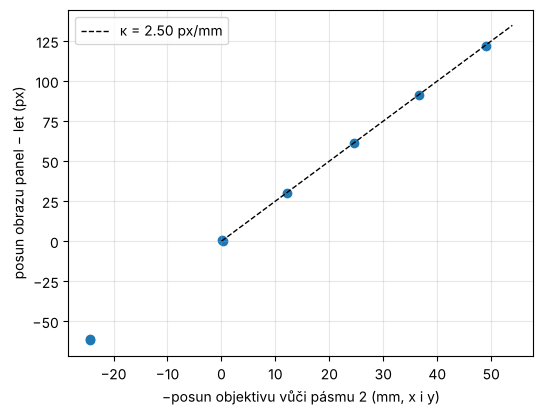

In [3]:
REF = 2                       # referenční pásmo (zelené), vůči němu jsou v metadatech posuny objektivů

def shift_sub(a, c):
    """Posun (dy, dx), o který je třeba posunout c, aby sedělo na a: fázová korelace gradientů se subpixelovým zpřesněním."""
    g = lambda z: np.hypot(*np.gradient(ndi.gaussian_filter(z, 1.5)))
    w = np.outer(np.hanning(a.shape[0]), np.hanning(a.shape[1]))
    F = np.fft.fft2(g(a) * w) * np.conj(np.fft.fft2(g(c) * w)); cc = np.fft.ifft2(F / (np.abs(F) + 1e-12)).real
    i, j = np.unravel_index(cc.argmax(), cc.shape); H, W = cc.shape
    def par(m, z, p): d = m - 2 * z + p; return 0.5 * (m - p) / d if d else 0.0
    dy = i + par(cc[i - 1, j], cc[i, j], cc[(i + 1) % H, j]); dx = j + par(cc[i, j - 1], cc[i, j], cc[i, (j + 1) % W])
    return np.array([dy - H if dy > H / 2 else dy, dx - W if dx > W / 2 else dx]), cc.max() / cc.std()

rows = {}
for b in range(1, 6):
    sp, _ = shift_sub(PANEL[REF][0], PANEL[b][0]); sf, _ = shift_sub(FLIGHT[REF][0], FLIGHT[b][0])
    tx, ty = FLIGHT[b][1]["rig_t"][:2]
    rows[FLIGHT[b][1]["band"]] = {"Tx (mm)": tx, "Ty (mm)": ty, "panel dx": sp[1], "panel dy": sp[0],
                                  "let dx": sf[1], "let dy": sf[0], "Δdx": sp[1] - sf[1], "Δdy": sp[0] - sf[0]}
par_tab = pd.DataFrame(rows).T
o = par_tab.drop(FLIGHT[REF][1]["band"])
T = np.r_[o["Tx (mm)"], o["Ty (mm)"]]; D = np.r_[o["Δdx"], o["Δdy"]]
kappa = -(T @ D) / (T @ T)                                    # px na mm posunu objektivu (rozdíl panel − let)
f, p = FLIGHT[REF][1]["f"], FLIGHT[REF][1]["pitch"]
H_panel = f / (p * kappa) / 1000                              # m; paralaxa letu (~1 px) zanedbaná
H_flight = FLIGHT[1][1]["alt"] - PANEL[1][1]["alt"] + H_panel # výška letu nad terénem podle rozdílu výšek GPS
par_tab["paralaxa letu (px)"] = np.hypot(par_tab["Tx (mm)"], par_tab["Ty (mm)"]) * f / (H_flight * 1000 * p)
print(par_tab.round(2).to_string())
print(f"paralaxa na snímku panelu {kappa:.2f} px na mm → kamera byla {H_panel:.2f} m nad panelem")
print(f"výška letu nad terénem ≈ {H_flight:.0f} m (GPS {FLIGHT[1][1]['alt']:.1f} − {PANEL[1][1]['alt']:.1f} m + {H_panel:.2f} m)")
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(-T, D, c="C0"); tt = np.linspace(0, 1.1 * np.abs(T).max(), 2)
ax.plot(tt, kappa * tt, "k--", lw=1, label=f"κ = {kappa:.2f} px/mm")
ax.set_xlabel("−posun objektivu vůči pásmu 2 (mm, x i y)"); ax.set_ylabel("posun obrazu panel − let (px)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

> **✏️ Úkol 1.** Proč se posun pásem na snímku panelu liší od posunu na snímku z letu o desítky pixelů, když jde o stejnou kameru? Z jaké vzdálenosti byl panel vyfocen a jak tomu odpovídá výška letu nad terénem? Spočítej paralaxu modrého pásma vůči zelenému při letu ve 30 m a při letu ve 40 m nad lesem s korunami vysokými 20 m (pro koruny i pro zem). Proč pak k sesazení pásem nestačí jeden posun pro celý snímek?

*Tvoje odpověď:* 

## 3. Měřítko a otočení pásem

Posun změříme zvlášť v každé dlaždici 256 × 256 pixelů a proložíme ho afinní transformací d = t + A · (x, y): t je posun ve středu, z matice A plyne rozdíl měřítka a otočení. Rozdíl měřítka by měl odpovídat poměru ohniskových vzdáleností, otočení třetímu úhlu RigRelatives (v metadatech ve stupních).

          posun t (px) měřítko (%) z ohniskových vzdáleností (%) otočení (°) RigRelatives, třetí úhel (°) rozptyl posunu po snímku (px) zbytek po afinní (px, medián)
Blue      [-8.5, -5.6]      -0.291                        -0.259       0.095                        0.097                         7.597                         0.233
Red         [3.2, 2.6]      -0.362                        -0.377      -0.045                       -0.047                         7.802                         0.455
NIR        [-2.5, 7.5]       0.009                        -0.063       0.122                        0.121                         5.040                         0.393
Red edge   [5.4, -1.6]      -0.315                        -0.363       0.032                        0.034                         6.369                         0.415


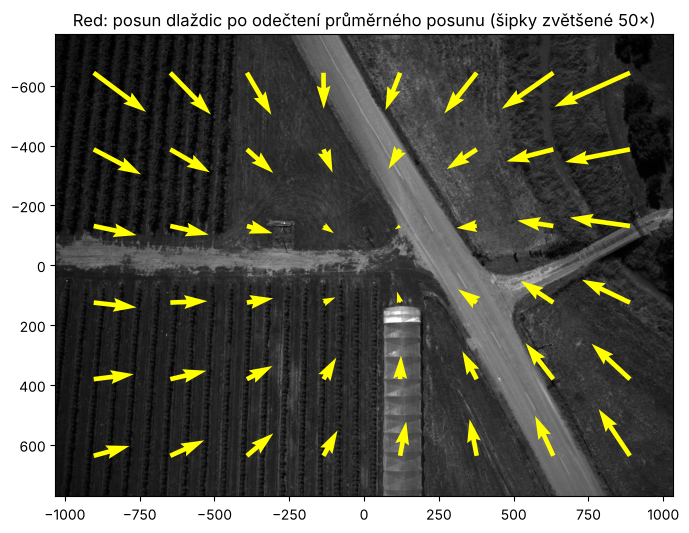

In [4]:
TILE = 256                    # ◀ parametr: velikost dlaždice (px)
BAND = 3                      # ◀ parametr: pásmo pro mapu posunů (1 modré, 3 červené, 4 NIR, 5 red edge)
ref = FLIGHT[REF][0]; Hh, Ww = ref.shape; cy0, cx0 = (Hh - 1) / 2, (Ww - 1) / 2

def tile_shifts(img):
    out = []
    for y0 in range(0, Hh - TILE + 1, TILE):
        for x0 in range(0, Ww - TILE + 1, TILE):
            s, q = shift_sub(ref[y0:y0 + TILE, x0:x0 + TILE], img[y0:y0 + TILE, x0:x0 + TILE])
            out.append((x0 + TILE / 2 - cx0, y0 + TILE / 2 - cy0, s[1], s[0], q))
    return np.array(out)

def fit_affine(r):
    """Posun d = t + A · (x, y) metodou nejmenších čtverců (souřadnice od středu snímku)."""
    X = np.c_[np.ones(len(r)), r[:, 0], r[:, 1]]
    cx = np.linalg.lstsq(X, r[:, 2], rcond=None)[0]; cy = np.linalg.lstsq(X, r[:, 3], rcond=None)[0]
    res = np.hypot(r[:, 2] - X @ cx, r[:, 3] - X @ cy)
    return np.array([cx[0], cy[0]]), np.array([[cx[1], cx[2]], [cy[1], cy[2]]]), res

AFF, rows = {}, {}
for b in range(1, 6):
    if b == REF: AFF[b] = (np.zeros(2), np.zeros((2, 2))); continue
    r = tile_shifts(FLIGHT[b][0]); t, A, res = fit_affine(r); AFF[b] = (t, A)
    m = FLIGHT[b][1]
    rows[m["band"]] = {"posun t (px)": np.round(t, 1), "měřítko (%)": 100 * (A[0, 0] + A[1, 1]) / 2,
                       "z ohniskových vzdáleností (%)": 100 * (FLIGHT[REF][1]["f"] / m["f"] - 1),
                       "otočení (°)": np.degrees((A[1, 0] - A[0, 1]) / 2), "RigRelatives, třetí úhel (°)": m["rig_r"][2],
                       "rozptyl posunu po snímku (px)": np.ptp(np.hypot(r[:, 2], r[:, 3])),
                       "zbytek po afinní (px, medián)": np.median(res)}
    if b == BAND: r_show = r
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3f}"))
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(ref, cmap="gray", extent=(-cx0, Ww - cx0, Hh - cy0, -cy0))
t = AFF[BAND][0]
ax.quiver(r_show[:, 0], r_show[:, 1], r_show[:, 2] - t[0], r_show[:, 3] - t[1], color="yellow", angles="xy", scale_units="xy", scale=0.02)
ax.set_title(f"{FLIGHT[BAND][1]['band']}: posun dlaždic po odečtení průměrného posunu (šipky zvětšené 50×)")
plt.show()

podíl pixelů s |ΔNDVI| > 0,05:
  střed snímku (třetina): 18.1 %
  okraj snímku (vnější pětina): 42.3 %
  hrany (strmý gradient NDVI): 66.7 %
  celý snímek: 36.3 %


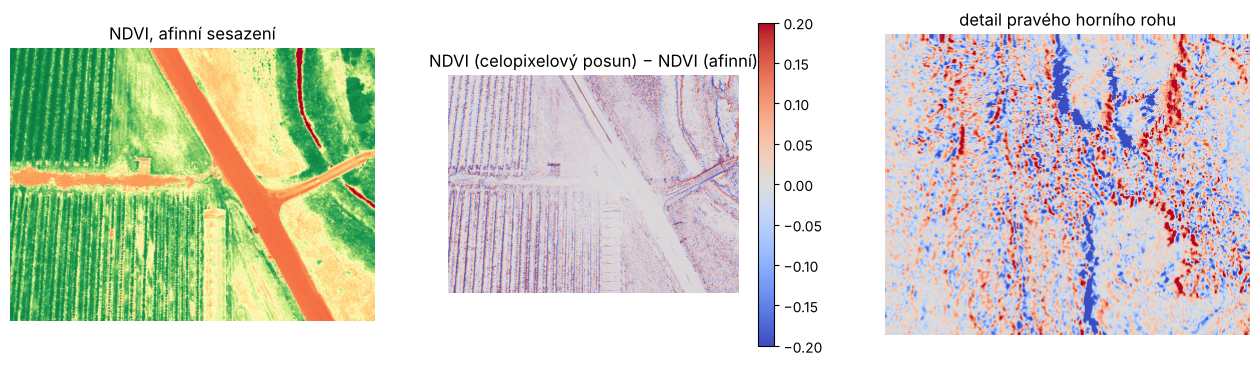

In [5]:
def warp(img, t, A):
    """Přenese pásmo na mřížku referenčního pásma: výstup(p) = vstup(p − t − A·p), souřadnice od středu."""
    Myx = np.array([[A[1, 1], A[1, 0]], [A[0, 1], A[0, 0]]])       # řádky (y, x)
    M = np.eye(2) - Myx; c = np.array([cy0, cx0])
    return ndi.affine_transform(img, M, offset=c - M @ c - t[::-1], order=1, mode="nearest")

L_fl = {b: radiance(*FLIGHT[b]) for b in range(1, 6)}
L_tr = {b: ndi.shift(L_fl[b], np.round(AFF[b][0][::-1]), order=0, mode="nearest") for b in L_fl}   # jen celopixelový posun jako v základní verzi
L_af = {b: warp(L_fl[b], *AFF[b]) for b in L_fl}
k = {b: PANEL[b][1]["albedo"] / radiance(*PANEL[b])[Path(np.array(PANEL[b][1]["area"]).reshape(-1, 2)).contains_points(
         np.c_[np.indices(PANEL[b][0].shape)[1].ravel(), np.indices(PANEL[b][0].shape)[0].ravel()]).reshape(PANEL[b][0].shape)].mean() for b in L_fl}
def refl(L): return {b: k[b] * L[b] * PANEL[b][1]["E_h"] / FLIGHT[b][1]["E_h"] for b in L}   # panel + DLS
ndvi = lambda R: (R[4] - R[3]) / (R[4] + R[3] + 1e-9)
RHO_tr, RHO_af = refl(L_tr), refl(L_af)
N_tr, N_af = ndvi(RHO_tr), ndvi(RHO_af)
dN = N_tr - N_af
yy, xx = np.indices(dN.shape); edge = np.maximum(np.abs(xx - cx0) / cx0, np.abs(yy - cy0) / cy0)
grad = np.hypot(*np.gradient(ndi.gaussian_filter(N_af, 1)))
print("podíl pixelů s |ΔNDVI| > 0,05:")
for name, msk in [("střed snímku (třetina)", edge < 1 / 3), ("okraj snímku (vnější pětina)", edge > 0.8),
                  ("hrany (strmý gradient NDVI)", grad > np.percentile(grad, 90)), ("celý snímek", edge >= 0)]:
    print(f"  {name}: {100 * np.mean(np.abs(dN[msk]) > 0.05):.1f} %")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].imshow(N_af, cmap="RdYlGn", vmin=-0.2, vmax=1); ax[0].set_title("NDVI, afinní sesazení")
im = ax[1].imshow(dN, cmap="coolwarm", vmin=-0.2, vmax=0.2); ax[1].set_title("NDVI (celopixelový posun) − NDVI (afinní)"); plt.colorbar(im, ax=ax[1])
r, c = slice(0, 300), slice(1700, 2064)
ax[2].imshow(dN[r, c], cmap="coolwarm", vmin=-0.2, vmax=0.2); ax[2].set_title("detail pravého horního rohu")
for a in ax: a.axis("off")
plt.show()

> **✏️ Úkol 2.** Proč se posun pásem mění po snímku (podívej se na šipky pro červené pásmo a pak pro NIR)? Souhlasí měřítko s poměrem ohniskových vzdáleností a otočení s RigRelatives? O kolik pixelů se v rohu snímku liší skutečný posun od posunu ve středu? Kde ve snímku a na kterých objektech se NDVI z celopixelového posunu (jako v základní verzi) liší od afinního sesazení nejvíc a proč právě tam?

*Tvoje odpověď:* 

## 4. Jak se chyba kalibrace přenáší do NDVI

Když má NIR relativní chybu e_NIR a červené pásmo e_Red, změní se NDVI přibližně o ΔNDVI ≈ (1 − NDVI²) / 2 · (e_NIR − e_Red). Společná chyba obou pásem se vyruší. Porovnáme vzorec s výpočtem na snímku a podíváme se, co s indexy udělá kalibrace jen z DLS bez panelu.

             ρ Red  ρ NIR   NDVI  ΔNDVI s chybou  ΔNDVI podle vzorce  ΔNDVI jen DLS   NDRE  ΔNDRE jen DLS
silnice      0.170  0.192  0.055           0.024               0.024          0.019  0.041          0.020
suchá louka  0.134  0.251  0.301           0.022               0.022          0.018  0.192          0.019
sad          0.016  0.308  0.897           0.005               0.005          0.004  0.452          0.016
poměr odrazivosti jen DLS / panel + DLS po pásmech: {'Blue': 0.642, 'Green': 0.785, 'Red': 0.908, 'NIR': 0.944, 'Red edge': 0.907}


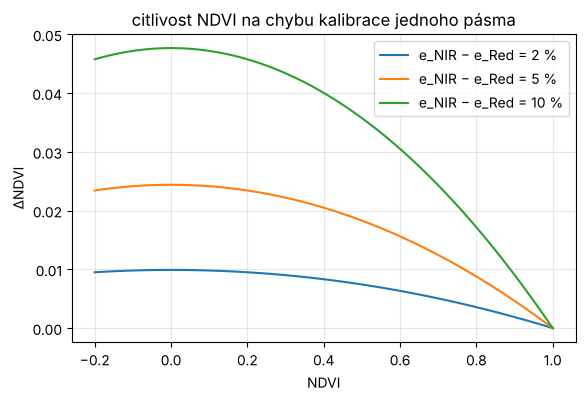

In [6]:
REGIONS = {"silnice": (slice(1140, 1260), slice(1570, 1650)), "suchá louka": (slice(100, 500), slice(1120, 1500)), "sad": (slice(20, 640), slice(20, 560))}   # ◀ parametr: oblasti (řádky, sloupce)
ERR_RED, ERR_NIR = 0.00, 0.05   # ◀ parametr: relativní chyba kalibrace červeného a NIR pásma (0,05 = +5 %)

R_ok = RHO_af
R_err = dict(R_ok); R_err[3] = R_ok[3] * (1 + ERR_RED); R_err[4] = R_ok[4] * (1 + ERR_NIR)
R_dls = {b: np.pi * L_af[b] / FLIGHT[b][1]["E_h"] for b in L_af}     # jen DLS
ndre = lambda R: (R[4] - R[5]) / (R[4] + R[5] + 1e-9)
rows = {}
for reg, (r, c) in REGIONS.items():
    n0 = np.median(ndvi(R_ok)[r, c])
    rows[reg] = {"ρ Red": np.median(R_ok[3][r, c]), "ρ NIR": np.median(R_ok[4][r, c]), "NDVI": n0,
                 "ΔNDVI s chybou": np.median(ndvi(R_err)[r, c]) - n0,
                 "ΔNDVI podle vzorce": (1 - n0 ** 2) / 2 * (np.log1p(ERR_NIR) - np.log1p(ERR_RED)),
                 "ΔNDVI jen DLS": np.median(ndvi(R_dls)[r, c]) - n0,
                 "NDRE": np.median(ndre(R_ok)[r, c]), "ΔNDRE jen DLS": np.median(ndre(R_dls)[r, c]) - np.median(ndre(R_ok)[r, c])}
print(pd.DataFrame(rows).T.round(3).to_string())
ratio = {FLIGHT[b][1]["band"]: np.median(R_dls[b] / R_ok[b]) for b in L_af}
print("poměr odrazivosti jen DLS / panel + DLS po pásmech:", {b: round(float(v), 3) for b, v in ratio.items()})
nn = np.linspace(-0.2, 1, 100)
fig, ax = plt.subplots(figsize=(6.5, 4))
for e in (0.02, 0.05, 0.10):
    ax.plot(nn, (1 - nn ** 2) / 2 * np.log1p(e), label=f"e_NIR − e_Red = {100 * e:.0f} %")
ax.set_xlabel("NDVI"); ax.set_ylabel("ΔNDVI"); ax.legend(); ax.grid(alpha=0.3); ax.set_title("citlivost NDVI na chybu kalibrace jednoho pásma")
plt.show()

> **✏️ Úkol 3.** Nastav ERR_NIR = 0,05 a ERR_RED = 0: proč se NDVI silnice a louky posune víc než NDVI sadu? Ověř vzorec pro ERR_RED = 0,05 a pro ERR_RED = ERR_NIR. Kalibrace jen z DLS dává odrazivost v jednotlivých pásmech jinou o jednotky až desítky procent (poměr vypsal výpočet), přesto se NDVI změní jen o setiny. Proč? Pro které úlohy tedy stačí DLS bez panelu a pro které ne?

*Tvoje odpověď:* 

## 5. Termální pásmo a vegetace

Termální pásmo ukládá teplotu v setinách kelvinu, vypočtenou s emisivitou 1,0. Skutečný povrch má emisivitu nižší a část záření, které kamera vidí, je odražená obloha. V přiblížení šedého tělesa σT_b⁴ = ε σT⁴ + (1 − ε) σT_obl⁴. Termokamera má hrubší pixel i jinou ohniskovou vzdálenost, proto NDVI zprůměrujeme na velikost termálního pixelu, přepočteme přes hlavní body objektivů a zbývající posun najdeme tak, aby korelace NDVI a teploty byla co nejsilnější.

velikost pixelu na zemi (GSD) ve výšce 97 m: {'Green': '4.3 cm', 'Panchro': '2.0 cm', 'LWIR': '26.2 cm'}


1 termální pixel = 6.15 pixelu MS; zpřesňující posun (13.0, -25.0) px MS; korelace NDVI a teploty r = -0.62
             termálních pixelů  T kamery (°C)  T při ε = 0.95  NDVI (na mřížce termokamery)
silnice                  260.0          38.40           40.95                          0.05
suchá louka             3965.0          39.49           42.07                          0.31
sad                     6666.0          29.28           31.57                          0.88
pro NDVI > 0,3: teplota klesá o 1.36 °C na 0,1 NDVI


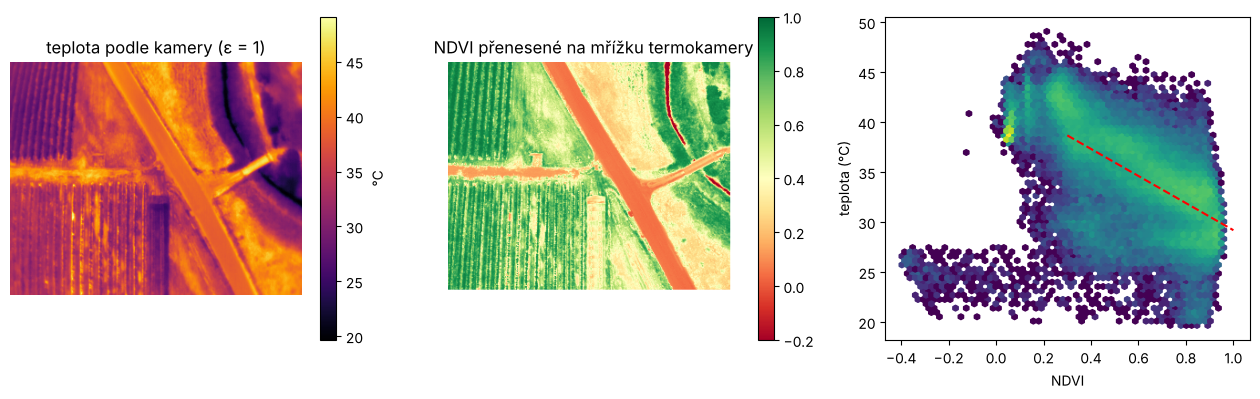

In [7]:
EPS = 0.95                    # ◀ parametr: emisivita povrchu pro opravu (kamera počítá s 1,0)
T_SKY = -30.0                 # ◀ parametr: jasová teplota oblohy (°C), předpoklad pro jasnou oblohu
dn_t, mt = FLIGHT[7]
Tb = dn_t / 100 - 273.15                                          # setiny kelvinu → °C
ms, mp = FLIGHT[REF][1], FLIGHT[6][1]
gsd = {FLIGHT[b][1]["band"]: 100 * H_flight * FLIGHT[b][1]["pitch"] / FLIGHT[b][1]["f"] for b in (REF, 6, 7)}
print(f"velikost pixelu na zemi (GSD) ve výšce {H_flight:.0f} m:", {b: f"{v:.1f} cm" for b, v in gsd.items()})

s_t = (ms["f"] / ms["pitch"]) / (mt["f"] / mt["pitch"])          # kolik pixelů MS připadá na jeden termální pixel
pp_ms = np.array(ms["pp"]) / ms["pitch"]; pp_t = np.array(mt["pp"]) / mt["pitch"]   # hlavní bod v pixelech (x, y)
N_box = ndi.uniform_filter(N_af, size=int(round(s_t)))
yt, xt = np.indices(Tb.shape)
def ndvi_on_thermal(d):
    xm = pp_ms[0] + (xt + 0.5 - pp_t[0]) * s_t - 0.5 + d[1]; ym = pp_ms[1] + (yt + 0.5 - pp_t[1]) * s_t - 0.5 + d[0]
    return ndi.map_coordinates(N_box, [ym, xm], order=1, cval=np.nan), ym, xm
def score(d):
    n, _, _ = ndvi_on_thermal(d); ok = np.isfinite(n) & (n != 0)
    return np.corrcoef(n[ok], Tb[ok])[0, 1]
best = min(((dy, dx) for dy in range(-80, 81, 4) for dx in range(-80, 81, 4)), key=score)        # hrubé hledání posunu
best = min(((best[0] + dy, best[1] + dx) for dy in np.arange(-4, 4.5, 0.5) for dx in np.arange(-4, 4.5, 0.5)), key=score)
N_t, ym, xm = ndvi_on_thermal(best)
print(f"1 termální pixel = {s_t:.2f} pixelu MS; zpřesňující posun ({best[0]:.1f}, {best[1]:.1f}) px MS; korelace NDVI a teploty r = {score(best):.2f}")

def t_corr(tb, eps, t_sky):
    """Oprava na emisivitu v přiblížení šedého tělesa: σT_b⁴ = ε σT⁴ + (1 − ε) σT_obl⁴."""
    K = 273.15
    return (((tb + K) ** 4 - (1 - eps) * (t_sky + K) ** 4) / eps) ** 0.25 - K
rows = {}
for reg, (r, c) in REGIONS.items():
    inside = (ym >= r.start) & (ym < r.stop) & (xm >= c.start) & (xm < c.stop)
    tb = np.median(Tb[inside])
    rows[reg] = {"termálních pixelů": inside.sum(), "T kamery (°C)": tb, f"T při ε = {EPS}": t_corr(tb, EPS, T_SKY),
                 "NDVI (na mřížce termokamery)": np.median(N_t[inside])}
print(pd.DataFrame(rows).T.round(2).to_string())
ok = np.isfinite(N_t)
veg = ok & (N_t > 0.3)
a, b0 = np.polyfit(N_t[veg], Tb[veg], 1)
print(f"pro NDVI > 0,3: teplota klesá o {-a / 10:.2f} °C na 0,1 NDVI")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
im = ax[0].imshow(Tb, cmap="inferno"); plt.colorbar(im, ax=ax[0], label="°C"); ax[0].set_title("teplota podle kamery (ε = 1)")
im = ax[1].imshow(N_t, cmap="RdYlGn", vmin=-0.2, vmax=1); plt.colorbar(im, ax=ax[1]); ax[1].set_title("NDVI přenesené na mřížku termokamery")
ax[2].hexbin(N_t[ok], Tb[ok], gridsize=60, bins="log", cmap="viridis"); ax[2].plot(nn := np.linspace(0.3, 1, 2), a * nn + b0, "r--")
ax[2].set_xlabel("NDVI"); ax[2].set_ylabel("teplota (°C)")
for x in ax[:2]: x.axis("off")
plt.show()

> **✏️ Úkol 4.** Jak velký je termální pixel na zemi a kolik multispektrálních pixelů do něj padne? Jak teplé jsou silnice, suchá louka a sad a čím se dá vysvětlit, že je sad o tolik chladnější? Najdi v grafu a na mapách body s NDVI pod nulou a nízkou teplotou: co to je? Nastav EPS na 0,97 (vegetace) a 0,92 (suchá půda) a T_SKY na −10 °C (oblačno): o kolik se teplota změní a je to víc, nebo méně než přesnost kamery?

*Tvoje odpověď:* 

## 6. Zostření panchromatickým pásmem

Panchromatické pásmo zachycuje široký rozsah vlnových délek (střed a šířka jsou v tabulce v kroku 1) s dvakrát jemnějším pixelem. Metoda HPM (high-pass modulation) vynásobí každé převzorkované pásmo poměrem pan / pan rozmazané na rozlišení MS. Pan nejdřív sesadíme s průměrem pásem 1–4 stejně jako v kroku 3.

1 pixel MS = 2.11 pixelu pan; pan proti MS: posun [ -0.7 -17.2] px MS, měřítko +0.13 %, otočení pan vůči MS -0.30° (RigRelatives -0.32°)
korelace pan a průměru pásem 1–4: bez opravy 0.514, s opravou 0.697; zbytek po afinní 1.08 px


největší rozdíl NDVI zostřeného a převzorkovaného: 1.8e-07
průměrná odrazivost Red před a po zostření: 0.1242 a 0.1241
podíl jemných detailů: Red převzorkované 0.064, Red zostřené 0.101, pan 0.153


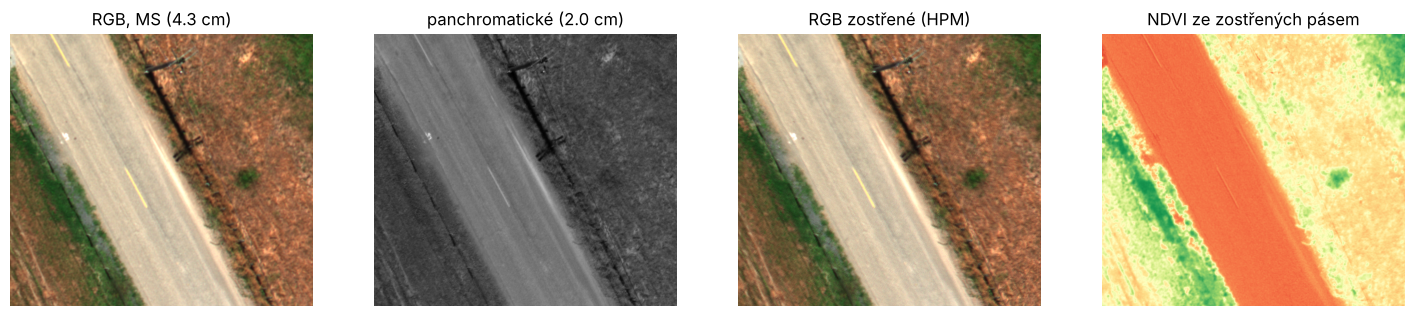

In [8]:
CROP = (slice(1000, 1400), slice(1400, 1850))    # ◀ parametr: výřez v pixelech MS (řádky, sloupce)
dn_p, mp = FLIGHT[6]
P = radiance(dn_p, mp)
s_p = (mp["f"] / mp["pitch"]) / (ms["f"] / ms["pitch"])          # kolik pixelů pan připadá na jeden pixel MS
pp_p = np.array(mp["pp"]) / mp["pitch"]
P_box = ndi.uniform_filter(P, size=int(round(s_p)))
cen = np.array([cx0, cy0])

def ms_to_pan(x, y, t, A):
    """Souřadnice pan (x, y) pro pixel MS (x, y): přepočet přes hlavní body a měřítko, opravený o posun t a afinní matici A."""
    xq = x + t[0] + A[0, 0] * (x - cen[0]) + A[0, 1] * (y - cen[1]); yq = y + t[1] + A[1, 0] * (x - cen[0]) + A[1, 1] * (y - cen[1])
    return pp_p[0] + (xq + 0.5 - pp_ms[0]) * s_p - 0.5, pp_p[1] + (yq + 0.5 - pp_ms[1]) * s_p - 0.5

intensity = sum(L_af[b] for b in (1, 2, 3, 4)) / 4
yy, xx = np.indices(intensity.shape)
def pan_on_ms(t, A):
    xp, yp = ms_to_pan(xx, yy, t, A)
    return ndi.map_coordinates(P_box, [yp, xp], order=1, cval=0)
P0 = pan_on_ms(np.zeros(2), np.zeros((2, 2)))
ref, ref_save = P0, ref                                        # dlaždice: pan (jen přepočet) proti průměru pásem 1–4
r_pan = tile_shifts(intensity); ref = ref_save
t_p, A_p, res_p = fit_affine(r_pan)
P_ms = pan_on_ms(t_p, A_p)
print(f"1 pixel MS = {s_p:.2f} pixelu pan; pan proti MS: posun {np.round(t_p, 1)} px MS, měřítko {100 * (A_p[0, 0] + A_p[1, 1]) / 2:+.2f} %, otočení pan vůči MS {-np.degrees((A_p[1, 0] - A_p[0, 1]) / 2):+.2f}° (RigRelatives {mp['rig_r'][2]:+.2f}°)")
print(f"korelace pan a průměru pásem 1–4: bez opravy {np.corrcoef(P0.ravel(), intensity.ravel())[0, 1]:.3f}, s opravou {np.corrcoef(P_ms.ravel(), intensity.ravel())[0, 1]:.3f}; zbytek po afinní {np.median(res_p):.2f} px")

# výřez na mřížce pan: pro každý pixel pan hledáme souřadnice MS (inverzní přepočet)
r, c = CROP
x0p, y0p = ms_to_pan(c.start, r.start, t_p, A_p); x1p, y1p = ms_to_pan(c.stop, r.stop, t_p, A_p)
yP, xP = np.mgrid[int(y0p):int(y1p), int(x0p):int(x1p)].astype(float)
qx = (xP + 0.5 - pp_p[0]) / s_p + pp_ms[0] - 0.5 - t_p[0] - cen[0]; qy = (yP + 0.5 - pp_p[1]) / s_p + pp_ms[1] - 0.5 - t_p[1] - cen[1]
Ai = np.linalg.inv(np.eye(2) + A_p)
xM = cen[0] + Ai[0, 0] * qx + Ai[0, 1] * qy; yM = cen[1] + Ai[1, 0] * qx + Ai[1, 1] * qy
pan_c = ndi.map_coordinates(P, [yP, xP], order=1)
up = {b: ndi.map_coordinates(RHO_af[b], [yM, xM], order=1) for b in (1, 2, 3, 4)}           # MS převzorkované na mřížku pan
pan_low = ndi.map_coordinates(P_ms, [yM, xM], order=1)                                      # pan rozmazané na rozlišení MS
sharp = {b: up[b] * pan_c / pan_low for b in up}                                            # HPM: MS × pan / pan_nízké
N_up, N_sh = ndvi(up), ndvi(sharp)
print(f"největší rozdíl NDVI zostřeného a převzorkovaného: {np.nanmax(np.abs(N_sh - N_up)):.1e}")
print(f"průměrná odrazivost Red před a po zostření: {up[3].mean():.4f} a {sharp[3].mean():.4f}")
hf = lambda a: np.std(a - ndi.gaussian_filter(a, 2)) / np.std(a)      # podíl jemných detailů (do ~2 pixelů pan)
print(f"podíl jemných detailů: Red převzorkované {hf(up[3]):.3f}, Red zostřené {hf(sharp[3]):.3f}, pan {hf(pan_c):.3f}")
rgb = lambda D: np.clip(np.dstack([D[3], D[2], D[1]]) / np.percentile(np.dstack([up[3], up[2], up[1]]), 99.5), 0, 1)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
ax[0].imshow(rgb(up)); ax[0].set_title(f"RGB, MS ({gsd[ms['band']]:.1f} cm)")
ax[1].imshow(pan_c, cmap="gray"); ax[1].set_title(f"panchromatické ({gsd[mp['band']]:.1f} cm)")
ax[2].imshow(rgb(sharp)); ax[2].set_title("RGB zostřené (HPM)")
ax[3].imshow(N_sh, cmap="RdYlGn", vmin=-0.2, vmax=1); ax[3].set_title("NDVI ze zostřených pásem")
for a in ax: a.axis("off")
plt.show()

> **✏️ Úkol 5.** Kolikrát jemnější je panchromatický pixel a o kolik se zvýšil podíl jemných detailů v červeném pásmu? Proč je NDVI ze zostřených pásem stejné jako z nezostřených (rozdíl je na úrovni zaokrouhlení)? Proč zostření nemění průměrnou odrazivost? Pan zahrnuje i část NIR: je zostřené červené pásmo u vegetace stejně věrohodné jako zostřené zelené? Uvaž, jak vegetace vypadá v pan a jak v červeném pásmu.

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Z tabulky GSD spočítej, v jaké výšce by měl termální pixel 10 cm a jaký by pak měly pixel multispektrální pásma. Kolikrát víc letových linií by to při stejném bočním překryvu znamenalo proti letu v 97 m? Ověř to v notebooku Plánovač letu dronu.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Snímky: MicaSense, Inc. (2017–2023). *imageprocessing* (licence MIT), https://github.com/micasense/imageprocessing, soubory data/ALTUM-PT/IMG_0000_*.tif a IMG_0010_*.tif a micasense/image.py (radiance, vinětace, termální pásmo).
- MicaSense: Altum and Altum-PT Thermal Band – FAQ, https://support.micasense.com/hc/en-us/articles/360036377834 (setiny kelvinu, emisivita 1,0, přesnost ±5 K).
- Zitová, B., Flusser, J. (2003). Image registration methods: a survey. *Image and Vision Computing* 21(11), 977–1000.
- Kuglin, C. D., Hines, D. C. (1975). The phase correlation image alignment method. *Proceedings of the IEEE International Conference on Cybernetics and Society*, 163–165.
- Vivone, G. a kol. (2015). A critical comparison among pansharpening algorithms. *IEEE Transactions on Geoscience and Remote Sensing* 53(5), 2565–2586.
- Norman, J. M., Becker, F. (1995). Terminology in thermal infrared remote sensing of natural surfaces. *Agricultural and Forest Meteorology* 77, 153–166.
- Carlson, T. N., Gillies, R. R., Perry, E. M. (1994). A method to make use of thermal infrared temperature and NDVI measurements to infer surface soil water content and fractional vegetation cover. *Remote Sensing Reviews* 9, 161–173.

### Jak citovat

OpenSkyLab (2026). Kalibrace multispektrální kamery, pokročilá verze: geometrie pásem, chyby NDVI, termální a panchromatické pásmo [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*